In [4]:
import h5py
import os

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 检查文件是否存在
if not os.path.exists(bfm_h5_path):
    print(f"Error: File not found at {bfm_h5_path}")
else:
    print(f"File found at {bfm_h5_path}")

# 加载 H5 文件并列出所有数据集
with h5py.File(bfm_h5_path, "r") as f:
    print("Datasets and groups in the file:")

    def print_dataset(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"  Dataset: {name}, Shape: {obj.shape}, Type: {obj.dtype}")
        elif isinstance(obj, h5py.Group):
            print(f"  Group: {name}")

    f.visititems(print_dataset)

    # 示例：根据实际路径读取数据
    try:
        # 根据正确路径加载形状数据
        shape_mean = f["shape/model/mean"][:]
        shape_pca = f["shape/model/pcaBasis"][:]
        shape_variance = f["shape/model/pcaVariance"][:]

        print(f"\nShape mean loaded, Shape: {shape_mean.shape}")
        print(f"Shape PCA basis loaded, Shape: {shape_pca.shape}")
        print(f"Shape PCA variance loaded, Shape: {shape_variance.shape}")
    except KeyError as e:
        print(f"Error: {str(e)}")

File found at /Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5
Datasets and groups in the file:
  Group: catalog
  Group: catalog/MorphableModel
  Dataset: catalog/MorphableModel/modelPath, Shape: (1,), Type: |S1
  Dataset: catalog/MorphableModel/modelType, Shape: (1,), Type: |S12
  Group: catalog/MorphableModel.color
  Dataset: catalog/MorphableModel.color/modelPath, Shape: (1,), Type: |S6
  Dataset: catalog/MorphableModel.color/modelType, Shape: (1,), Type: |S23
  Group: catalog/MorphableModel.expression
  Dataset: catalog/MorphableModel.expression/modelPath, Shape: (1,), Type: |S11
  Dataset: catalog/MorphableModel.expression/modelType, Shape: (1,), Type: |S23
  Group: catalog/MorphableModel.shape
  Dataset: catalog/MorphableModel.shape/modelPath, Shape: (1,), Type: |S7
  Dataset: catalog/MorphableModel.shape/modelType, Shape: (1,), Type: |S18
  Group: color
  Group: color/model
  Dataset: color/model/mean, Shape: (159447,), Ty

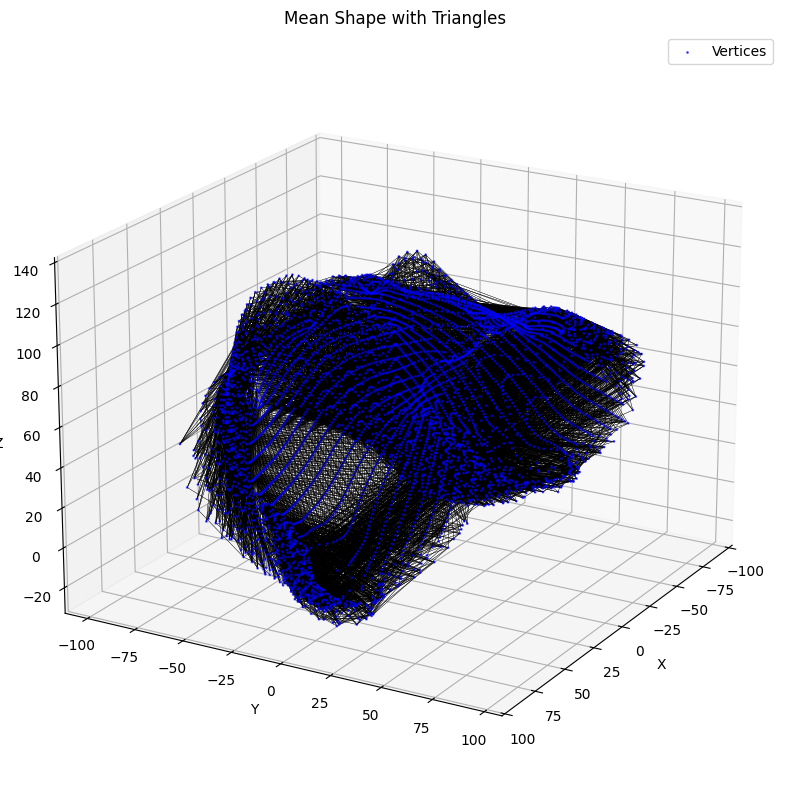

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际路径

# 加载 HDF5 数据
with h5py.File(bfm_h5_path, "r") as f:
    # 加载形状数据
    shape_mean = f["shape/model/mean"][:]
    shape_pca_basis = f["shape/model/pcaBasis"][:]
    shape_pca_variance = f["shape/model/pcaVariance"][:]

    # 加载三角形网格
    triangles = f["shape/representer/cells"][:].T  # 转置为 (105694, 3)

# 将形状均值重塑为 (53149, 3)
vertices = shape_mean.reshape(-1, 3)


def visualize_3d(vertices, triangles=None, title="3D Model"):
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(
        vertices[:, 0],
        vertices[:, 1],
        vertices[:, 2],
        s=1,
        c="blue",
        alpha=0.6,
        label="Vertices",
    )

    # 如果提供了三角形网格，则绘制网格
    if triangles is not None:
        for tri in triangles:
            if np.all(tri < vertices.shape[0]):  # 检查索引范围
                tri_vertices = vertices[tri]
                ax.plot(
                    [tri_vertices[0][0], tri_vertices[1][0]],
                    [tri_vertices[0][1], tri_vertices[1][1]],
                    [tri_vertices[0][2], tri_vertices[1][2]],
                    color="black",
                    linewidth=0.2,
                )
                ax.plot(
                    [tri_vertices[1][0], tri_vertices[2][0]],
                    [tri_vertices[1][1], tri_vertices[2][1]],
                    [tri_vertices[1][2], tri_vertices[2][2]],
                    color="black",
                    linewidth=0.2,
                )
                ax.plot(
                    [tri_vertices[2][0], tri_vertices[0][0]],
                    [tri_vertices[2][1], tri_vertices[0][1]],
                    [tri_vertices[2][2], tri_vertices[0][2]],
                    color="black",
                    linewidth=0.2,
                )

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.view_init(elev=20, azim=30)
    plt.legend()
    plt.show()


# 调用可视化函数
visualize_3d(vertices[::10], triangles, title="Mean Shape with Triangles")

In [ ]:
# 生成随机 PCA 权重
np.random.seed(42)
random_weights = np.random.randn(shape_pca_variance.shape[0]) * np.sqrt(
    shape_pca_variance
)

# 计算随机形状
random_shape = shape_mean + shape_pca_basis.dot(random_weights)
random_vertices = random_shape.reshape(-1, 3)

# 可视化随机形状
visualize_3d(random_vertices, triangles, title="Random Shape")

KeyboardInterrupt: 

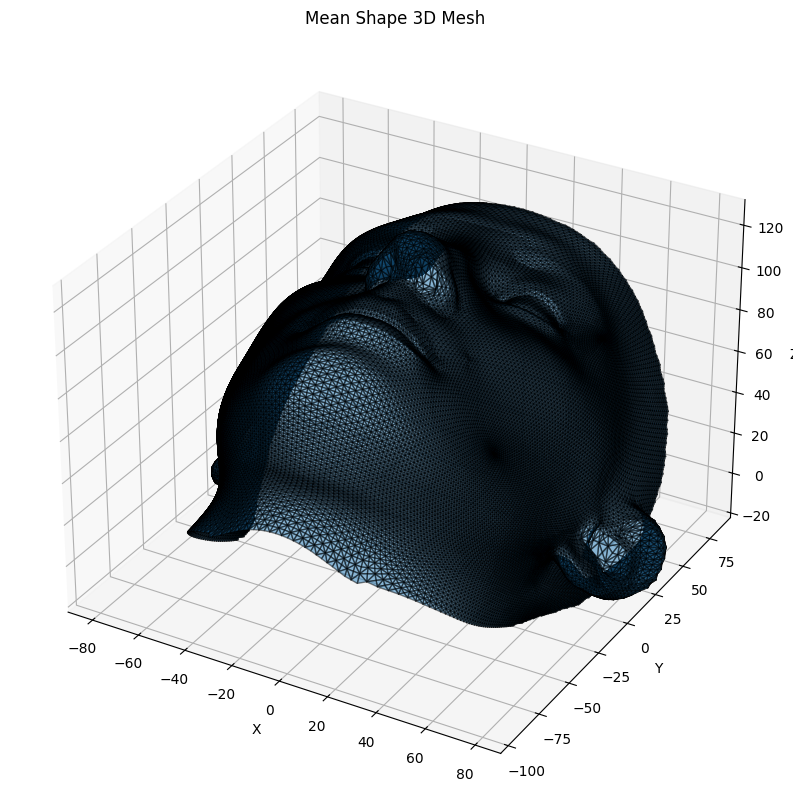

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 加载 HDF5 数据
with h5py.File(bfm_h5_path, "r") as f:
    # 加载形状数据
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T  # 转置为 (105694, 3)

# 将形状均值重塑为 (53149, 3)
vertices = shape_mean.reshape(-1, 3)


# 3D 网格可视化
def visualize_3d_mesh(vertices, triangles, title="3D Mesh Model"):
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection="3d")

    # 创建 Poly3DCollection
    mesh = Poly3DCollection(vertices[triangles], alpha=0.5, edgecolor="k")
    ax.add_collection3d(mesh)

    # 设置轴范围
    ax.set_xlim(vertices[:, 0].min(), vertices[:, 0].max())
    ax.set_ylim(vertices[:, 1].min(), vertices[:, 1].max())
    ax.set_zlim(vertices[:, 2].min(), vertices[:, 2].max())

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.show()


# 调用函数可视化
visualize_3d_mesh(vertices, triangles, title="Mean Shape 3D Mesh")

/Users/ai/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/Users/ai/anaconda3/lib/python3.10/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


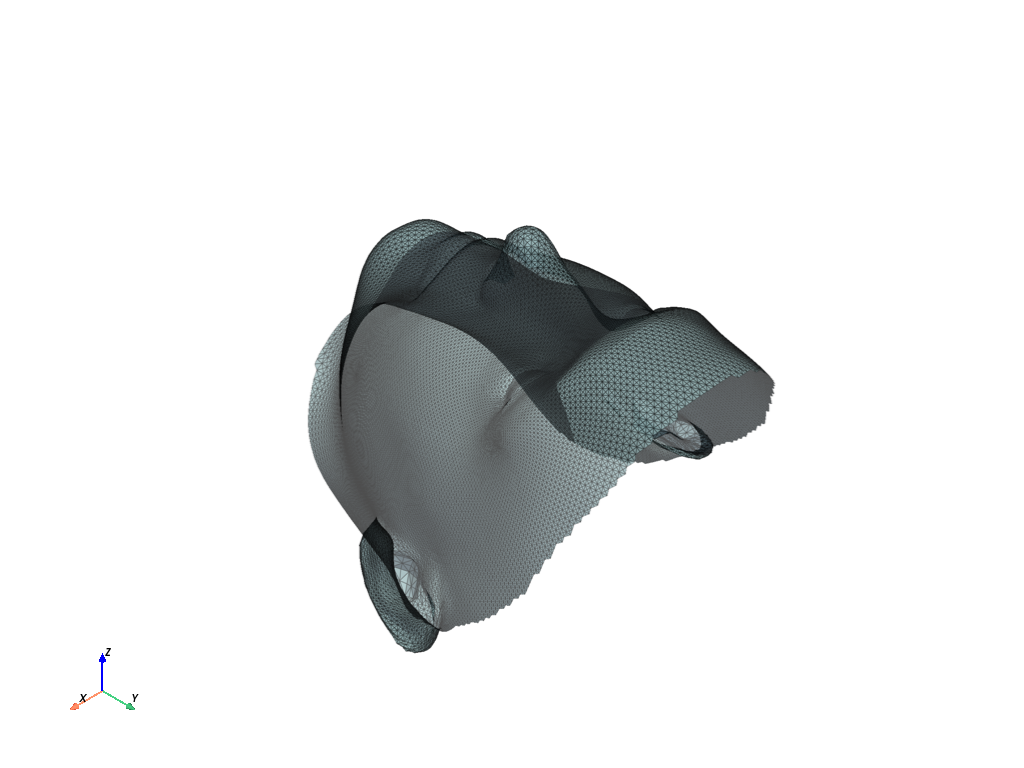

AttributeError: 'Plotter' object has no attribute 'camera_azimuth'

In [4]:
import h5py
import numpy as np
import pyvista as pv

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 加载数据
with h5py.File(bfm_h5_path, "r") as f:
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T

# 重塑顶点数据
vertices = shape_mean.reshape(-1, 3)

# 创建 PyVista 网格
mesh = pv.PolyData(
    vertices,
    np.hstack([np.full((triangles.shape[0], 1), 3), triangles]).astype(np.int32),
)

# 设置旋转
plotter = pv.Plotter()
plotter.add_mesh(mesh, color="lightblue", show_edges=True, opacity=0.7)
plotter.show_axes()  # 显示坐标轴
plotter.enable_anti_aliasing()  # 平滑渲染

# 自动旋转
plotter.open_gif("rotating_mesh.gif")  # 如果想导出动画
plotter.show(auto_close=False)
plotter.camera_position = "xy"
for _ in range(360):
    plotter.camera_azimuth(1)  # 每次旋转 1 度
    plotter.write_frame()  # 保存到 gif（可选）

plotter.close()

/Users/ai/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/Users/ai/anaconda3/lib/python3.10/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


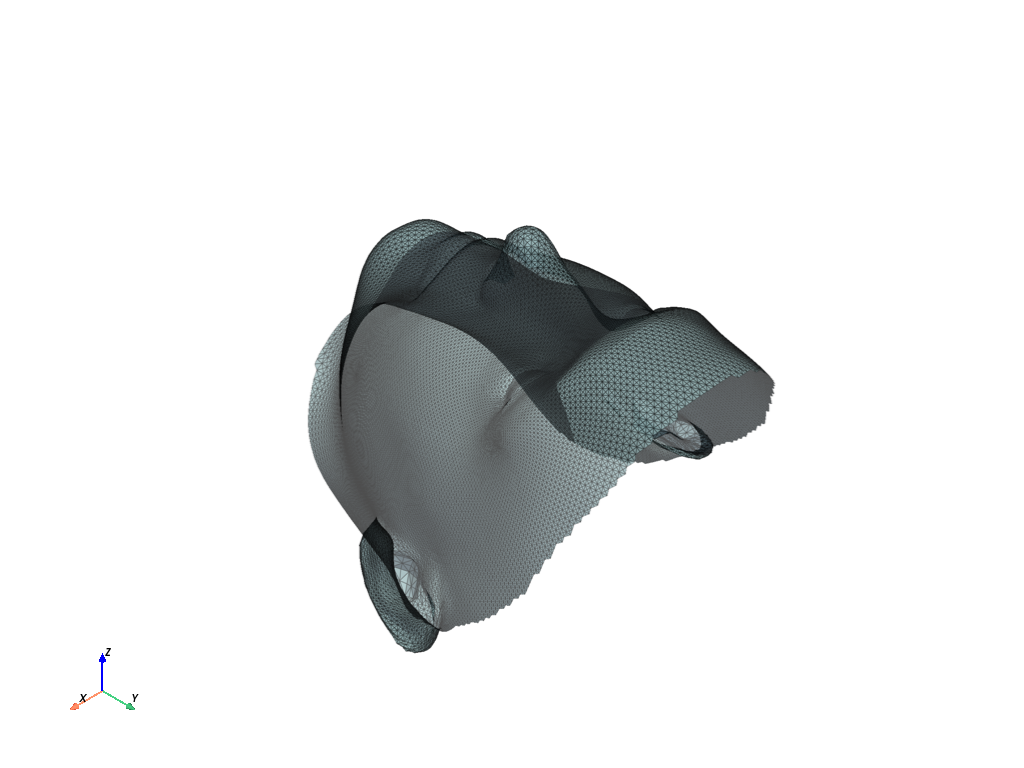

AttributeError: 'CameraPosition' object has no attribute 'rotate_azimuth'

In [ ]:
import h5py
import numpy as np
import pyvista as pv

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 加载数据
with h5py.File(bfm_h5_path, "r") as f:
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T

# 重塑顶点数据
vertices = shape_mean.reshape(-1, 3)

# 创建 PyVista 网格
mesh = pv.PolyData(
    vertices,
    np.hstack([np.full((triangles.shape[0], 1), 3), triangles]).astype(np.int32),
)

# 初始化渲染器
plotter = pv.Plotter()
plotter.add_mesh(mesh, color="lightblue", show_edges=True, opacity=0.7)
plotter.show_axes()  # 显示坐标轴
plotter.enable_anti_aliasing()  # 平滑渲染

# 自动旋转
plotter.open_gif("rotating_mesh.gif")  # 可选：保存动画为 GIF
plotter.show(auto_close=False)

# 旋转动画
for _ in range(360):  # 每次旋转 1 度，共 360 度
    plotter.camera_position = plotter.camera_position.rotate_azimuth(
        1
    )  # 正确的旋转方法
    plotter.write_frame()  # 保存帧到 GIF（可选）

plotter.close()

/Users/ai/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/Users/ai/anaconda3/lib/python3.10/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


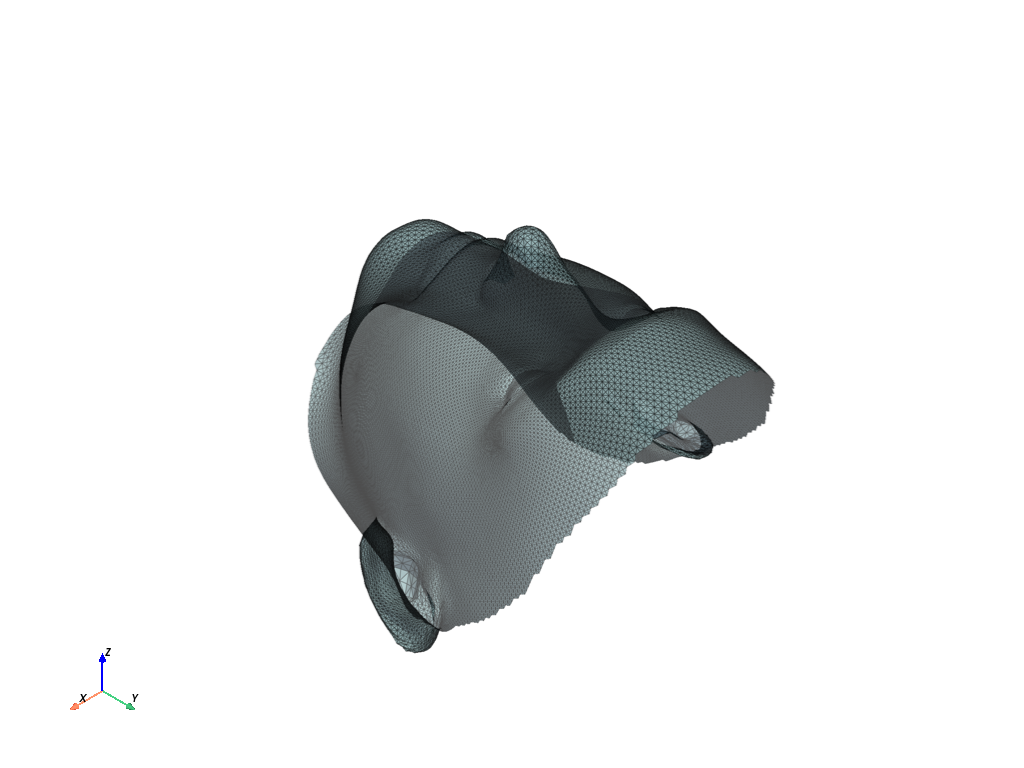

TypeError: 'float' object is not callable

In [ ]:
import h5py
import numpy as np
import pyvista as pv

bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 加载数据
with h5py.File(bfm_h5_path, "r") as f:
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T

# 重塑顶点数据
vertices = shape_mean.reshape(-1, 3)

# 创建 PyVista 网格
mesh = pv.PolyData(
    vertices,
    np.hstack([np.full((triangles.shape[0], 1), 3), triangles]).astype(np.int32),
)

# 初始化渲染器
plotter = pv.Plotter()
plotter.add_mesh(mesh, color="lightblue", show_edges=True, opacity=0.7)
plotter.show_axes()  # 显示坐标轴
plotter.enable_anti_aliasing()  # 平滑渲染

# 自动旋转
plotter.open_gif("rotating_mesh.gif")  # 可选：保存动画为 GIF
plotter.show(auto_close=False)

# 使用相机的 azimuth 方法旋转
for _ in range(360):  # 每次旋转 1 度，共 360 度
    plotter.camera.azimuth(1)  # 绕模型旋转相机
    plotter.write_frame()  # 保存帧到 GIF（可选）

plotter.close()

/Users/ai/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/Users/ai/anaconda3/lib/python3.10/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


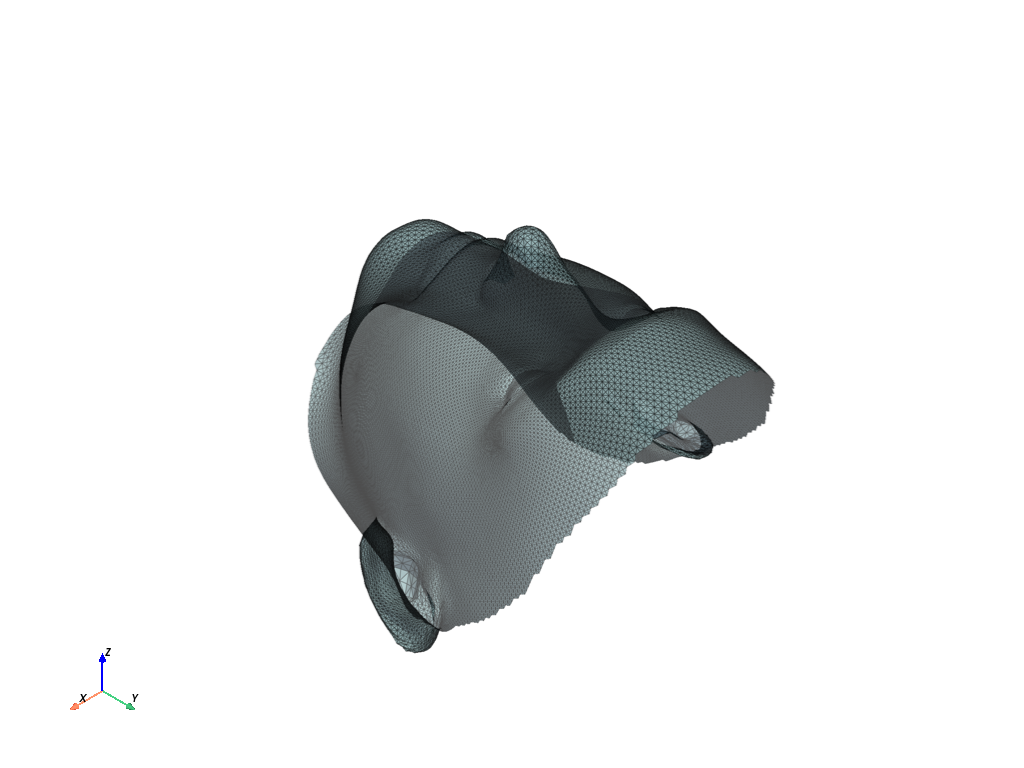

TypeError: 'float' object is not callable

In [ ]:
import h5py
import numpy as np
import pyvista as pv

# 文件路径
bfm_h5_path = "/Users/ai/Downloads/studium/5_3dscan/3_project/face-reconstruction/models/BFM/model2017-1_bfm_nomouth.h5"  # 替换为实际的 BFM 文件路径

# 加载数据
with h5py.File(bfm_h5_path, "r") as f:
    shape_mean = f["shape/model/mean"][:]
    triangles = f["shape/representer/cells"][:].T

# 重塑顶点数据
vertices = shape_mean.reshape(-1, 3)

# 创建 PyVista 网格
mesh = pv.PolyData(
    vertices,
    np.hstack([np.full((triangles.shape[0], 1), 3), triangles]).astype(np.int32),
)

# 初始化渲染器
plotter = pv.Plotter()
plotter.add_mesh(mesh, color="lightblue", show_edges=True, opacity=0.7)
plotter.show_axes()  # 显示坐标轴
plotter.enable_anti_aliasing()  # 平滑渲染

# 自动旋转
plotter.open_gif("rotating_mesh.gif")  # 可选：保存动画为 GIF
plotter.show(auto_close=False)

plotter.camera.azimuth = 45.0

plotter.close()